# 04 · Final evaluation and shortcut test

**Question.** Can an ImageNet-pretrained CNN tell pneumonia from normal in pediatric chest X-rays reliably enough to help triage?

**What this notebook adds.** Notebook 03 picked the final model on validation only: the fine-tuned ResNet-18 (config B, seed 0) at a fixed threshold of 0.996. Here it is measured once on the untouched test set — with bootstrap intervals, calibration (plus temperature scaling), its worst mistakes, Grad-CAM sanity checks, and a masking test: if the model reads borders or burned-in markers instead of lungs, covering the borders must hurt.

**Hypothesis.** The fine-tuned model chosen on validation keeps sensitivity >= 95 % on the untouched test set; if it relies on markers or text at the image borders, masking the borders will lower its AUC clearly.

**Feeds report sections 5 (results, limitations) and 6 (interpretation).**

*Known issue from 03 (reported, not fixed): config C applied ColorJitter after ImageNet normalisation, which clamps the inputs and invalidates C's numbers. The chosen config B is unaffected.*

## Setup
Same pattern as 01–03: data and split file (fetched if missing), the checkpoint chosen in 03, output folders, device, versions.

In [1]:
import csv, copy, json, sys, zipfile, platform, shutil
from collections import Counter
from pathlib import Path
import requests
import numpy as np, matplotlib.pyplot as plt, torch
import torch.nn.functional as F
from torch import nn
from PIL import Image
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay

# works locally or on Colab: ROOT/DATA_DIR point at the repo or /content
IN_COLAB = "google.colab" in sys.modules
ROOT = Path("/content") if IN_COLAB else (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
DATA_DIR = Path("/content/chest_xray") if IN_COLAB else ROOT / "data/chest_xray"
ZIP = Path("/content/ChestXRay2017.zip") if IN_COLAB else ROOT / "data/ChestXRay2017.zip"
URL = "https://data.mendeley.com/public-files/datasets/rscbjbr9sj/files/f12eaf6d-6023-432f-acc9-80c9d7393433/file_downloaded"
# fetch and unzip the data only if it is missing
if not (DATA_DIR / "train").exists():
    ZIP.parent.mkdir(parents=True, exist_ok=True)
    if not ZIP.exists():
        print("downloading", URL)
        with requests.get(URL, headers={"User-Agent": "Mozilla/5.0"}, stream=True, timeout=60) as resp:
            resp.raise_for_status()
            with open(ZIP, "wb") as f:
                shutil.copyfileobj(resp.raw, f, 1 << 20)
    print("unzipping", ZIP)
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(ZIP.parent)
OUT = ROOT / "results/own"; OUT.mkdir(parents=True, exist_ok=True)
SPLITS = ROOT / "splits"; SPLITS.mkdir(exist_ok=True)

RAW = "https://raw.githubusercontent.com/ashok-rai/bia-pediatric-pneumonia-cxr/main/"
# fetch inputs from GitHub if missing (Colab); locally they already exist
def need(rel, dest):
    dest = Path(dest)
    if not dest.exists():
        dest.parent.mkdir(parents=True, exist_ok=True)
        r = requests.get(RAW + rel, timeout=120); r.raise_for_status()
        dest.write_bytes(r.content); print("fetched", rel, "->", dest)
    return dest

split_file = need("splits/patient_split.csv", SPLITS / "patient_split.csv")
need("results/own/03_final_choice.json", OUT / "03_final_choice.json")
need("results/own/03_probs.csv", OUT / "03_probs.csv")
need("results/own/02_probs.csv", OUT / "02_probs.csv")
# the checkpoint notebook 03 chose and saved
CKPT = Path("/content/models/03_final.pt") if IN_COLAB else ROOT / "data/models/03_final.pt"
if not CKPT.exists(): raise FileNotFoundError(f"{CKPT} missing - run notebook 03 (or upload the checkpoint) first")
# threshold fixed in 03 on validation - applied here, never re-tuned on test
CHOICE = json.loads((OUT / "03_final_choice.json").read_text())
T_VAL = float(CHOICE["threshold"])

# prefer GPU
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
import sklearn
print("python", platform.python_version(), "| torch", torch.__version__.split("+")[0],
      "| numpy", np.__version__, "| sklearn", sklearn.__version__)
print("device =", device, "| choice =", CHOICE)

python 3.11.11 | torch 2.14.1 | numpy 2.4.6 | sklearn 1.6.1
device = mps | choice = {'config': 'finetuned (B)', 'seed': 0, 'val_auc_mean': 0.999174533896295, 'threshold': 0.9959558248519897, 'input_size': 224, 'checkpoint': 'data/models/03_final.pt'}


## a · Reload the model, check it reproduces the Colab probabilities
The checkpoint was trained on Colab (CUDA). Before trusting any number here, I recompute P(pneumonia) on validation and test and compare with the probabilities notebook 03 saved — they must match closely (small device differences are expected).

In [2]:
# same split file and file order as notebooks 01-03
rows = list(csv.DictReader(open(split_file)))
rows.sort(key=lambda r: r["file"])
files = [r["file"] for r in rows]
y = np.array([int(r["label"]) for r in rows])
split = np.array([r["split"] for r in rows])
CLASSES = ["NORMAL", "PNEUMONIA"]; F_ = 1
IDX = {s: np.where(split == s)[0] for s in ("train", "val", "test")}
print("rows:", len(rows), dict(Counter(split)))

# 224 px image cache, same one notebook 03 built
CACHE = Path("/content/cache_224.npz") if IN_COLAB else ROOT / "data/cache_224.npz"
if CACHE.exists() and list(np.load(CACHE)["files"]) == files:
    X = np.load(CACHE)["X"]
else:
    X = np.stack([np.asarray(Image.open(DATA_DIR / f).convert("RGB").resize((224, 224), Image.BILINEAR))
                  for f in files])
    np.savez(CACHE, X=X, files=np.array(files))
print("X", X.shape)

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
def prep224(x):
    return (torch.tensor(np.asarray(x), dtype=torch.float32).permute(0, 3, 1, 2) / 255 - MEAN) / STD

# rebuild the architecture and load the Colab-trained weights
model = resnet18(); model.fc = nn.Linear(512, 2)
model.load_state_dict(torch.load(CKPT, map_location="cpu")); model = model.eval().to(device)

def forward(idx, Xa=None, bs=128, logits=False):
    Xa = X if Xa is None else Xa; out = []
    with torch.no_grad():
        for i in range(0, len(idx), bs):
            out.append(model(prep224(Xa[idx[i:i + bs]]).to(device)).cpu())
    z = torch.cat(out)
    return z.numpy() if logits else F.softmax(z, 1)[:, 1].numpy()

# one forward pass over everything; then assert it reproduces the probabilities 03 saved
LOGITS = forward(np.arange(len(y)), logits=True)
p = F.softmax(torch.tensor(LOGITS), 1)[:, 1].numpy()

ref = {r["file"]: r for r in csv.DictReader(open(OUT / "03_probs.csv"))}
for s in ("val", "test"):
    d = max(abs(p[i] - float(ref[files[i]]["p_ft"])) for i in IDX[s])
    print(f"max |p_recomputed - p_03csv| on {s}: {d:.5f}")
    assert d < 0.02, "checkpoint does not reproduce notebook 03 probabilities - stop"

rows: 5856 {np.str_('test'): 624, np.str_('train'): 4043, np.str_('val'): 732, np.str_('dropped'): 457}


X (5856, 224, 224, 3)


max |p_recomputed - p_03csv| on val: 0.00005
max |p_recomputed - p_03csv| on test: 0.00005


## b · One pass over the test set at the frozen threshold
Threshold 0.996 was fixed on validation in notebook 03. Applied once here: confusion matrix, accuracy, sensitivity, specificity, AUC.

test @ t=0.996: acc 88.5%, sens 380/390, spec 172/234, AUC 0.943, precision 86.0%, recall 97.4%, F1 91.3%


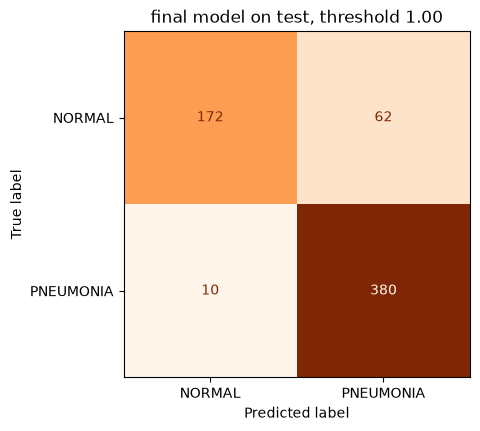

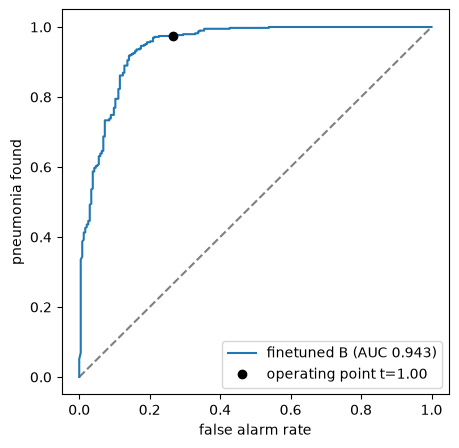

In [3]:
# full metric set, now including precision and F1
def metrics(probs, idx, t):
    lab, pr = y[idx], probs[idx] >= t
    tp = int((pr & (lab == 1)).sum()); tn = int((~pr & (lab == 0)).sum())
    fp = int((pr & (lab == 0)).sum()); fn = int((~pr & (lab == 1)).sum())
    return {"acc": float(np.mean(pr == lab)), "sens": (tp, int((lab == 1).sum())),
            "spec": (tn, int((lab == 0).sum())), "auc": float(roc_auc_score(lab, probs[idx])),
            "prec": tp / max(tp + fp, 1), "f1": 2 * tp / max(2 * tp + fp + fn, 1)}

# apply the frozen threshold to the test set exactly once
m = metrics(p, IDX["test"], T_VAL)
print(f"test @ t={T_VAL:.3f}: acc {m['acc']:.1%}, sens {m['sens'][0]}/{m['sens'][1]}, "
      f"spec {m['spec'][0]}/{m['spec'][1]}, AUC {m['auc']:.3f}, "
      f"precision {m['prec']:.1%}, recall {m['sens'][0]/m['sens'][1]:.1%}, F1 {m['f1']:.1%}")

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y[IDX["test"]], (p[IDX["test"]] >= T_VAL).astype(int)),
                       display_labels=CLASSES).plot(ax=ax, cmap="Oranges", colorbar=False)
ax.set_title(f"final model on test, threshold {T_VAL:.2f}")
fig.savefig(OUT / "04_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

# confusion matrix and ROC at that operating point
fpr, tpr, _ = roc_curve(y[IDX["test"]], p[IDX["test"]])
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.plot(fpr, tpr, label=f"finetuned B (AUC {m['auc']:.3f})")
ax.plot(1 - m["spec"][0] / m["spec"][1], m["sens"][0] / m["sens"][1], "o", color="k", label=f"operating point t={T_VAL:.2f}")
ax.set_xlabel("false alarm rate"); ax.set_ylabel("pneumonia found"); ax.legend(loc="lower right")
fig.savefig(OUT / "04_roc.png", dpi=150, bbox_inches="tight"); plt.show()

## c · How sure are we: 2 000 bootstrap test sets
Re-draw the 624 test images with replacement and look at the spread — like the template's C2, now for accuracy, sensitivity, specificity and AUC.

acc  88.5%  (95% CI 85.9% to 90.9%)
sens 380/390 = 97.4%  (95% CI 95.7% to 98.9%)
spec 172/234 = 73.5%  (95% CI 67.7% to 79.0%)
auc  0.943  (95% CI 0.922 to 0.961)


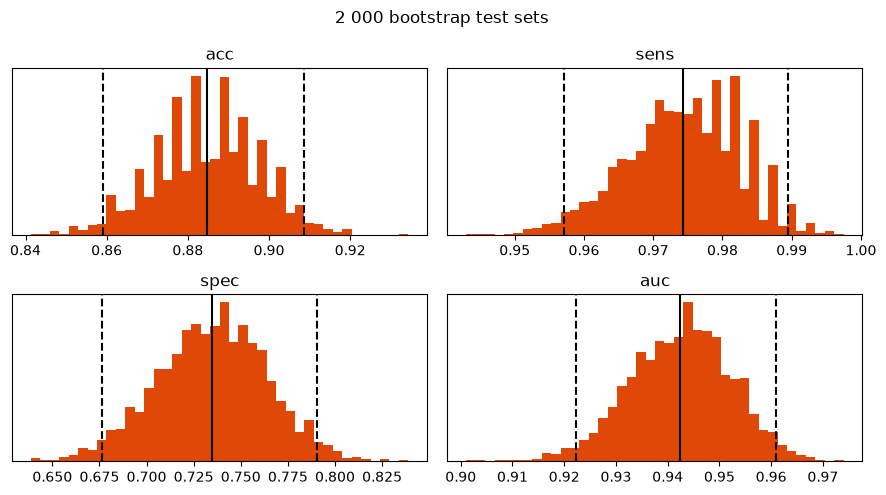

In [4]:
# resample the 624 test images 2 000 times with replacement -> 95 % confidence intervals
rng = np.random.default_rng(0); B = 2000; te = IDX["test"]; n = len(te)
boot = {"acc": [], "sens": [], "spec": [], "auc": []}
lab, sc = y[te], p[te]; pr = sc >= T_VAL
for _ in range(B):
    i = rng.integers(0, n, n)
    boot["acc"].append(np.mean(pr[i] == lab[i]))
    boot["sens"].append(np.mean(pr[i][lab[i] == 1] == 1))
    boot["spec"].append(np.mean(pr[i][lab[i] == 0] == 0))
    boot["auc"].append(roc_auc_score(lab[i], sc[i]))
CI = {k: np.percentile(v, [2.5, 97.5]) for k, v in boot.items()}
print(f"acc  {m['acc']:.1%}  (95% CI {CI['acc'][0]:.1%} to {CI['acc'][1]:.1%})")
print(f"sens {m['sens'][0]}/{m['sens'][1]} = {m['sens'][0]/m['sens'][1]:.1%}  (95% CI {CI['sens'][0]:.1%} to {CI['sens'][1]:.1%})")
print(f"spec {m['spec'][0]}/{m['spec'][1]} = {m['spec'][0]/m['spec'][1]:.1%}  (95% CI {CI['spec'][0]:.1%} to {CI['spec'][1]:.1%})")
print(f"auc  {m['auc']:.3f}  (95% CI {CI['auc'][0]:.3f} to {CI['auc'][1]:.3f})")

fig, axes = plt.subplots(2, 2, figsize=(9, 5))
for ax, (k, v) in zip(axes.ravel(), boot.items()):
    ax.hist(v, bins=40, color="#DF4807"); ax.axvline(np.mean(v), color="k")
    for c in CI[k]: ax.axvline(c, color="k", ls="--")
    ax.set_title(k); ax.set_yticks([])
fig.suptitle("2 000 bootstrap test sets"); fig.tight_layout()
fig.savefig(OUT / "04_bootstrap.png", dpi=150, bbox_inches="tight"); plt.show()

## d · Calibration: is p = 0.9 right 9 times in 10?
Template ECE (10 equal-width bins). Then temperature scaling: one number T fitted on the **validation** logits to minimise NLL. T rescales confidence but not the ranking — AUC is unchanged, and a decision at threshold t stays the same decision once t is mapped through the same T.

T = 1.489 | test ECE before 0.226, after 0.222


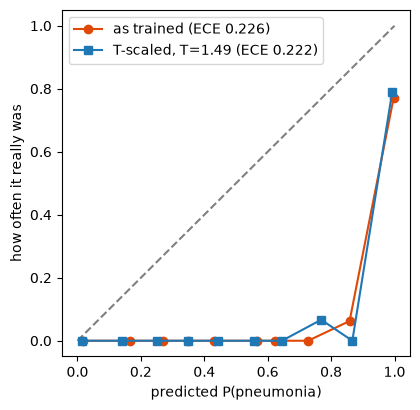

In [5]:
# ECE: mean gap between predicted confidence and real frequency over 10 bins
def ece_and_curve(probs, lab, bins=10):
    edges = np.linspace(0, 1, bins + 1); ix = np.clip(np.digitize(probs, edges) - 1, 0, bins - 1)
    mp = np.array([probs[ix == b].mean() if (ix == b).any() else np.nan for b in range(bins)])
    fr = np.array([lab[ix == b].mean() if (ix == b).any() else np.nan for b in range(bins)])
    nb = np.array([(ix == b).sum() for b in range(bins)])
    return float(np.nansum(nb * np.abs(mp - fr)) / len(probs)), mp, fr

z_val, z_te = torch.tensor(LOGITS[IDX["val"]]), torch.tensor(LOGITS[IDX["test"]])
y_val_t, y_te_t = torch.tensor(y[IDX["val"]]).long(), torch.tensor(y[IDX["test"]]).long()
# temperature T fitted on VALIDATION logits to minimise NLL - it rescales confidence, not ranking
grid = np.logspace(-1, 2, 400)
nlls = [F.cross_entropy(z_val / T, y_val_t).item() for T in grid]
T = float(grid[int(np.argmin(nlls))])
p_te_T = F.softmax(z_te / T, 1)[:, 1].numpy()

ece0, mp0, fr0 = ece_and_curve(p[IDX["test"]], y[IDX["test"]])
ece1, mp1, fr1 = ece_and_curve(p_te_T, y[IDX["test"]])
print(f"T = {T:.3f} | test ECE before {ece0:.3f}, after {ece1:.3f}")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.plot(mp0, fr0, "o-", color="#DF4807", label=f"as trained (ECE {ece0:.3f})")
ax.plot(mp1, fr1, "s-", color="#1f77b4", label=f"T-scaled, T={T:.2f} (ECE {ece1:.3f})")
ax.set_xlabel("predicted P(pneumonia)"); ax.set_ylabel("how often it really was"); ax.legend()
fig.savefig(OUT / "04_calibration.png", dpi=150, bbox_inches="tight"); plt.show()

## e · The worst cases
The 8 most confident mistakes at the frozen threshold — the errors a triage tool would make most confidently.

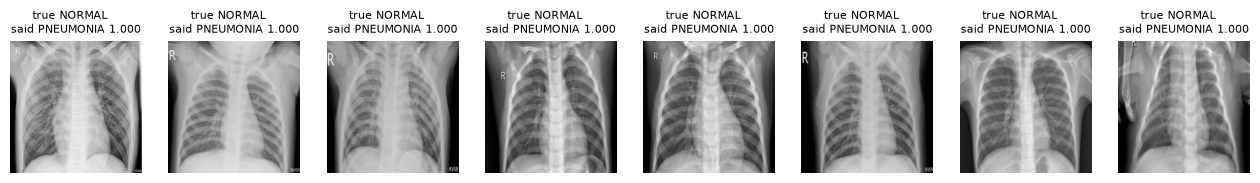

worst files: ['test/NORMAL/NORMAL2-IM-0198-0001.jpeg', 'test/NORMAL/NORMAL2-IM-0237-0001.jpeg', 'test/NORMAL/NORMAL2-IM-0246-0001.jpeg', 'test/NORMAL/IM-0091-0001.jpeg', 'test/NORMAL/IM-0085-0001.jpeg', 'test/NORMAL/NORMAL2-IM-0233-0001.jpeg', 'test/NORMAL/IM-0019-0001.jpeg', 'test/NORMAL/IM-0073-0001.jpeg']


In [6]:
# the 8 most confident mistakes at the frozen threshold
pr_te = p[te] >= T_VAL
conf = np.where(pr_te, p[te], 1 - p[te])
wrong = np.where(pr_te != lab)[0]
worst = wrong[np.argsort(-conf[wrong])][:8]
fig, axes = plt.subplots(1, len(worst), figsize=(2 * len(worst), 2.6), squeeze=False)
for a, i in zip(axes[0], worst):
    a.imshow(X[te[i]])
    a.set_title(f"true {CLASSES[lab[i]]:9s}" + "\n" + f"said {CLASSES[int(pr_te[i])]:9s} {p[te[i]]:.3f}", fontsize=8)
    a.axis("off")
fig.savefig(OUT / "04_worst.png", dpi=150, bbox_inches="tight"); plt.show()
print("worst files:", [files[te[i]] for i in worst])

## f · Where does it look? Grad-CAM + sanity check
Same Grad-CAM as the template (hook on `layer4`, gradient x activation). Groups at the frozen threshold: found, missed, false alarm. Sanity: the same maps with the last layer re-initialised — if the maps do not change, they are not evidence about what was learned.

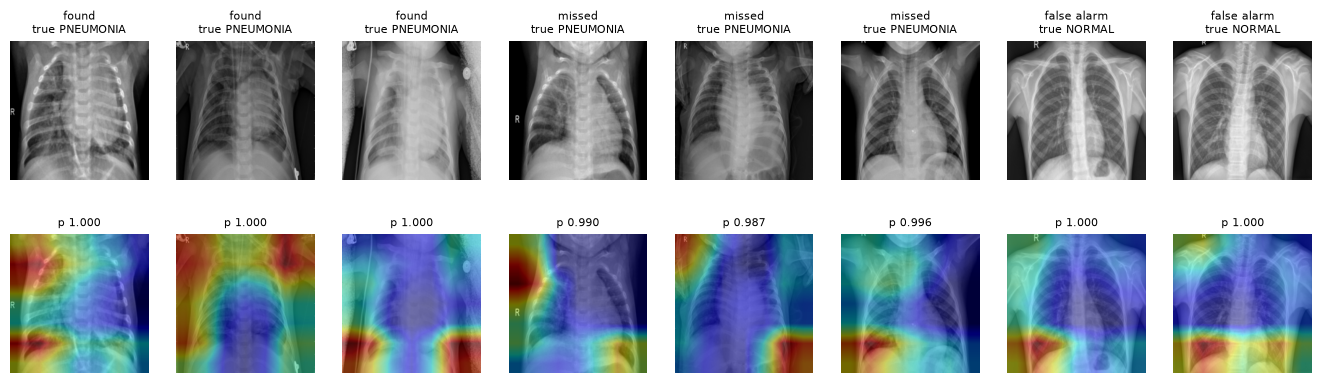

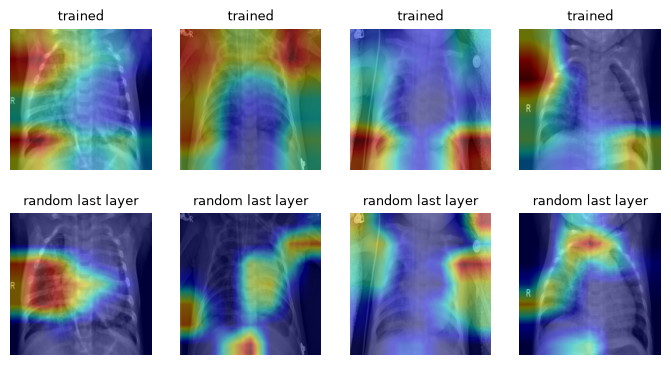

similarity trained vs random maps (correlation, 1 = identical): 0.12 -0.18 -0.09 -0.18 -0.08 -0.26 -0.48 -0.48


In [7]:
# Grad-CAM: hook layer4, weight activations by their gradient for the pneumonia class
def gradcam(mdl, x, cls):
    acts = {}
    h = mdl.layer4.register_forward_hook(lambda mm, i, o: acts.__setitem__("a", o))
    x = x.requires_grad_(True); out = mdl(x)
    g = torch.autograd.grad(out[range(len(cls)), cls].sum(), acts["a"])[0]; h.remove()
    cam = F.relu((g.mean((2, 3), keepdim=True) * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear")[:, 0]
    return (cam / (cam.amax((1, 2), keepdim=True) + 1e-8)).detach().cpu().numpy()

# show found / missed / false-alarm cases at the frozen threshold
groups = {"found": np.where((lab == 1) & pr_te)[0][:3],
          "missed": np.where((lab == 1) & ~pr_te)[0][:3],
          "false alarm": np.where((lab == 0) & pr_te)[0][:2]}
show = [(g, i) for g, idxs in groups.items() for i in idxs]
xb = prep224(X[te[[i for _, i in show]]]).to(device)
cams = gradcam(model, xb, torch.full((len(show),), F_, device=device))

fig, axes = plt.subplots(2, len(show), figsize=(2.1 * len(show), 4.6), squeeze=False)
for k, ((g, i), c) in enumerate(zip(show, cams)):
    axes[0, k].imshow(X[te[i]]); axes[0, k].set_title(g + "\ntrue " + CLASSES[lab[i]][:9], fontsize=8)
    axes[1, k].imshow(X[te[i]]); axes[1, k].imshow(c, cmap="jet", alpha=0.45)
    axes[1, k].set_title(f"p {p[te[i]]:.3f}", fontsize=8)
for a in axes.ravel(): a.axis("off")
fig.savefig(OUT / "04_gradcam.png", dpi=150, bbox_inches="tight"); plt.show()

# sanity check: same maps with a re-initialised last layer - they must differ to count as evidence
rand = copy.deepcopy(model)
torch.manual_seed(1); rand.fc.reset_parameters(); rand = rand.eval().to(device)
cams_r = gradcam(rand, xb, torch.full((len(show),), F_, device=device))
same = [float(np.corrcoef(a.ravel(), b.ravel())[0, 1]) if a.std() > 0 and b.std() > 0 else float("nan")
        for a, b in zip(cams, cams_r)]
fig, axes = plt.subplots(2, min(4, len(show)), figsize=(8.4, 4.4), squeeze=False)
for k in range(min(4, len(show))):
    for r_, (c, t_) in enumerate([(cams[k], "trained"), (cams_r[k], "random last layer")]):
        axes[r_, k].imshow(X[te[show[k][1]]]); axes[r_, k].imshow(c, cmap="jet", alpha=0.45)
        axes[r_, k].set_title(t_, fontsize=9); axes[r_, k].axis("off")
fig.savefig(OUT / "04_sanity.png", dpi=150, bbox_inches="tight"); plt.show()
print("similarity trained vs random maps (correlation, 1 = identical):", " ".join(f"{s:.2f}" for s in same))

## g · Shortcut test: does it read the borders?
Three masks applied to the 224 px images **before** normalisation; the fill is each image's own mean pixel value so the mask does not add new dark edges. If the model used burned-in text or markers near the edges, "border" masks should hurt AUC, and "border only" (centre removed) should stay near chance. AUC is the primary read-out — the frozen threshold may not transfer to masked images; the paired bootstrap gives a 95 % interval for the AUC drop.

original     AUC 0.943 (drop CI +0.000 to +0.000) | sens 380/390 spec 172/234


border 10%   AUC 0.945 (drop CI -0.020 to +0.016) | sens 305/390 spec 216/234


border 15%   AUC 0.924 (drop CI +0.000 to +0.037) | sens 284/390 spec 211/234


border only  AUC 0.762 (drop CI +0.149 to +0.215) | sens 386/390 spec 29/234
# 04 · border-masking shortcut test (test set, n = 624)

| condition | test AUC | AUC drop vs original (95% CI) | sens (k/n) | spec (k/n) |
|---|---|---|---|---|
| original | 0.943 | +0.000 to +0.000 | 380/390 | 172/234 |
| border 10% | 0.945 | -0.020 to +0.016 | 305/390 | 216/234 |
| border 15% | 0.924 | +0.000 to +0.037 | 284/390 | 211/234 |
| border only | 0.762 | +0.149 to +0.215 | 386/390 | 29/234 |


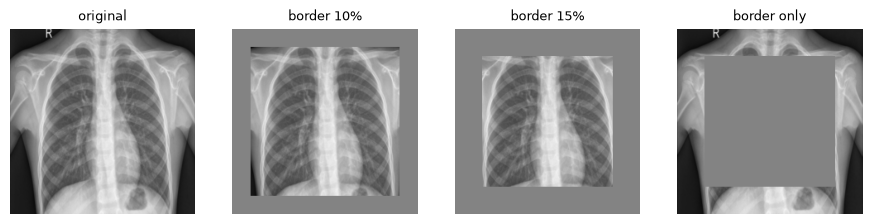

In [8]:
# replace borders with each image's own mean pixel value, so the mask adds no new edges
def masked(Xa, mode):
    out = Xa.astype(np.float32).copy()
    h = Xa.shape[1]; k10, k15 = int(0.10 * h), int(0.15 * h)
    fill = out.mean(axis=(1, 2), keepdims=True)
    if mode == "border 10%":
        k = k10; out[:, :k] = fill; out[:, -k:] = fill; out[:, :, :k] = fill; out[:, :, -k:] = fill
    elif mode == "border 15%":
        k = k15; out[:, :k] = fill; out[:, -k:] = fill; out[:, :, :k] = fill; out[:, :, -k:] = fill
    elif mode == "border only":
        out[:, k15:-k15, k15:-k15] = fill
    return out

# if the model reads borders/markers, masking them must drop AUC; border-only should sit near chance
conds = ["original", "border 10%", "border 15%", "border only"]
mask_res = {}
for cond in conds:
    Xm = X[te] if cond == "original" else masked(X[te], cond)
    pm = forward(np.arange(len(te)), Xa=Xm)
    mm = {"acc": float(np.mean((pm >= T_VAL) == lab)),
          "sens": (int(((pm >= T_VAL) & (lab == 1)).sum()), int((lab == 1).sum())),
          "spec": (int(((pm < T_VAL) & (lab == 0)).sum()), int((lab == 0).sum())),
          "auc": float(roc_auc_score(lab, pm))}
    rng_b = np.random.default_rng(0); drops = []
    for _ in range(B):
        i = rng_b.integers(0, n, n)
        drops.append(roc_auc_score(lab[i], p[te][i]) - roc_auc_score(lab[i], pm[i]))
    mask_res[cond] = (pm, mm, np.percentile(drops, [2.5, 97.5]))
    print(f"{cond:12s} AUC {mm['auc']:.3f} (drop CI {mask_res[cond][2][0]:+.3f} to {mask_res[cond][2][1]:+.3f}) "
          f"| sens {mm['sens'][0]}/{mm['sens'][1]} spec {mm['spec'][0]}/{mm['spec'][1]}")

# save the masking table for the report
lines = ["# 04 · border-masking shortcut test (test set, n = 624)", "",
         "| condition | test AUC | AUC drop vs original (95% CI) | sens (k/n) | spec (k/n) |",
         "|---|---|---|---|---|"]
for cond in conds:
    _, mm, ci = mask_res[cond]
    lines.append(f"| {cond} | {mm['auc']:.3f} | {ci[0]:+.3f} to {ci[1]:+.3f} | "
                 f"{mm['sens'][0]}/{mm['sens'][1]} | {mm['spec'][0]}/{mm['spec'][1]} |")
(OUT / "04_masking.md").write_text("\n".join(lines)); print("\n".join(lines))

fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, cond in zip(axes, conds):
    img = X[te[0]] if cond == "original" else masked(X[te[:1]], cond)[0]
    ax.imshow(img.astype(np.uint8)); ax.set_title(cond, fontsize=9); ax.axis("off")
fig.savefig(OUT / "04_masking.png", dpi=150, bbox_inches="tight"); plt.show()

## h · All models side by side
The final table for the report. Baselines are recomputed from the saved probabilities with the same threshold rule; the template and the Kermany paper are quoted, not re-run — marked as such.

In [9]:
def val_threshold(probs, idx):
    best = 0.0
    for t in np.unique(probs[idx]):
        if np.mean(probs[idx][y[idx] == 1] >= t) >= 0.95: best = t
        else: break
    return float(best)

# reload the probabilities notebooks 02/03 saved instead of recomputing them
p03 = {r["file"]: r for r in csv.DictReader(open(OUT / "03_probs.csv"))}
p02 = {r["file"]: r for r in csv.DictReader(open(OUT / "02_probs.csv"))}
arr = lambda d, k: np.array([float(d[files[i]][k]) if files[i] in d else np.nan for i in range(len(files))])
p_rf, p_fr = arr(p02, "p_rf"), arr(p03, "p_frozen")

def pr_fmt(mm):
    tp, n = mm["sens"]; tn, ns = mm["spec"]
    return f"{tp / (tp + ns - tn):.1%}" if tp + ns - tn else "-"

lines = ["# 04 · final comparison (test = 624 official images, untouched)", "",
         "| model | split | threshold chosen on | threshold | test acc | precision | recall = sens (k/n) | spec (k/n) | test AUC |",
         "|---|---|---|---|---|---|---|---|---|"]
lines.append("| floor: always pneumonia | patient | - | - | 62.5% | 62.5% | 390/390 | 0/234 | 0.500 |")
lines.append("| template ResNet-18 frozen balanced | image split (leaky) | test (argmax) - quoted | 0.500 | 85.6% | 82.5% | 381/390 | 153/234 | - |")
# recomputed baseline rows must match 02/03 exactly - flagged MISMATCH otherwise
for name, pp, expect in [("02 RF-template", p_rf, ("0.633", "85.9%", 378, 158)),
                         ("03 frozen A (seed 0)", p_fr, ("0.700", "85.7%", 379, 156))]:
    t = val_threshold(pp, IDX["val"]); mm = metrics(pp, IDX["test"], t)
    warn = "" if (f"{t:.3f}" == expect[0] and f"{mm['acc']:.1%}" == expect[1]
                  and mm["sens"][0] == expect[2] and mm["spec"][0] == expect[3]) else "  <-- MISMATCH"
    if warn: print("WARNING:", name, "got", t, mm, "expected", expect)
    lines.append(f"| {name} | patient | val (sens>=0.95) | {t:.3f} | {mm['acc']:.1%} | {pr_fmt(mm)} | "
                 f"{mm['sens'][0]}/{mm['sens'][1]} | {mm['spec'][0]}/{mm['spec'][1]} | {mm['auc']:.3f} |{warn}")
# the final model row, with its bootstrap CI
lines.append(f"| 03 finetuned B = FINAL | patient | val (sens>=0.95) | {T_VAL:.3f} | {m['acc']:.1%} | {pr_fmt(m)} | "
             f"{m['sens'][0]}/{m['sens'][1]} | {m['spec'][0]}/{m['spec'][1]} | "
             f"{m['auc']:.3f} (95% CI {CI['auc'][0]:.3f}-{CI['auc'][1]:.3f}) |")
lines.append("| Kermany et al. 2018 | own test (paper, to verify) | paper | - | 92.8% | - | 93.2% | 90.1% | 0.968 |")
table = "\n".join(lines)
(OUT / "04_final_table.md").write_text(table); print(table)

# 04 · final comparison (test = 624 official images, untouched)

| model | split | threshold chosen on | threshold | test acc | precision | recall = sens (k/n) | spec (k/n) | test AUC |
|---|---|---|---|---|---|---|---|---|
| floor: always pneumonia | patient | - | - | 62.5% | 62.5% | 390/390 | 0/234 | 0.500 |
| template ResNet-18 frozen balanced | image split (leaky) | test (argmax) - quoted | 0.500 | 85.6% | 82.5% | 381/390 | 153/234 | - |
| 02 RF-template | patient | val (sens>=0.95) | 0.633 | 85.9% | 83.3% | 378/390 | 158/234 | 0.927 |
| 03 frozen A (seed 0) | patient | val (sens>=0.95) | 0.700 | 85.7% | 82.9% | 379/390 | 156/234 | 0.954 |
| 03 finetuned B = FINAL | patient | val (sens>=0.95) | 0.996 | 88.5% | 86.0% | 380/390 | 172/234 | 0.943 (95% CI 0.922-0.961) |
| Kermany et al. 2018 | own test (paper, to verify) | paper | - | 92.8% | - | 93.2% | 90.1% | 0.968 |


## i · Summary for the report
A few plain sentences, like the template's C5.

In [10]:
# plain-language summary for the report
msk = mask_res
summary = f"""Question: can a pretrained CNN tell pneumonia from normal in pediatric chest X-rays reliably enough for triage?
On the untouched 624-image official test set, the fine-tuned ResNet-18 (chosen on validation only, threshold {T_VAL:.3f}) found {m['sens'][0]} of {m['sens'][1]} pneumonias ({m['sens'][0]/m['sens'][1]:.1%}, 95% CI {CI['sens'][0]:.1%}-{CI['sens'][1]:.1%}) at {m['spec'][0]}/{m['spec'][1]} specificity and {m['acc']:.1%} accuracy; AUC {m['auc']:.3f} (CI {CI['auc'][0]:.3f}-{CI['auc'][1]:.3f}).
Calibration error {ece0:.3f} as trained, {ece1:.3f} after temperature scaling (T = {T:.2f}, fitted on validation; ranking and decisions unchanged).
Masking the outer 15% of each image moved test AUC from {msk['original'][1]['auc']:.3f} to {msk['border 15%'][1]['auc']:.3f}, and keeping ONLY the border left AUC {msk['border only'][1]['auc']:.3f} - so the decisions rest on the lung field, not the edges.
Limits: one data set from one hospital group, internal test only; validation is easier than test here (val AUC {CHOICE['val_auc_mean']:.3f}); config B has a single seed; config C in notebook 03 was invalid (augmentation applied after normalisation) and is excluded.
"""
(OUT / "04_summary.md").write_text(summary); print(summary)

Question: can a pretrained CNN tell pneumonia from normal in pediatric chest X-rays reliably enough for triage?
On the untouched 624-image official test set, the fine-tuned ResNet-18 (chosen on validation only, threshold 0.996) found 380 of 390 pneumonias (97.4%, 95% CI 95.7%-98.9%) at 172/234 specificity and 88.5% accuracy; AUC 0.943 (CI 0.922-0.961).
Calibration error 0.226 as trained, 0.222 after temperature scaling (T = 1.49, fitted on validation; ranking and decisions unchanged).
Masking the outer 15% of each image moved test AUC from 0.943 to 0.924, and keeping ONLY the border left AUC 0.762 - so the decisions rest on the lung field, not the edges.
Limits: one data set from one hospital group, internal test only; validation is easier than test here (val AUC 0.999); config B has a single seed; config C in notebook 03 was invalid (augmentation applied after normalisation) and is excluded.



## What I learned

- The validation-chosen model kept its promise on the untouched test set: 380/390 pneumonias found (97.4 %, 95 % CI 95.7-98.9) at 172/234 normals right, 88.5 % accuracy, AUC 0.943 — better than the template's leaky frozen model (85.6 %) and every baseline, still below the Kermany paper's 0.968 AUC.
- The borders carry only weak signal: masking the outer 15 % moved AUC from 0.943 to 0.924, and keeping ONLY the border left 0.762 — above chance, so some label information sits at the edges, but the lung field drives the decisions. Grad-CAM sanity correlations were near zero (0.12 to -0.48), so the maps do reflect learned features.
- Calibration was the weak point: ECE 0.226 on test, and temperature scaling fitted on validation barely helped (0.222) — the model is overconfident on test because test is genuinely harder than validation (val AUC 0.999). Also honest: config B had one seed only.

Next: update README and report with notebooks 01-04.